# Exploratory data analysis

Runs `checkpoint1.eda`. Set `CELEBA_SPOOF_ROOT`; `EDA_N_SAMPLE` is the number of images for the pixel statistics or `all` (default).

In [1]:
import os
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

if Path.cwd().name == 'notebooks':
    os.chdir('..')

from scipy import stats as scipy_stats

from checkpoint1 import data, eda

fig_dir = Path(os.environ.get('EDA_FIG_DIR', 'outputs/figures'))
out_dir = Path(os.environ.get('EDA_OUT_DIR', 'outputs/eda'))
n_sample = os.environ.get('EDA_N_SAMPLE', 'all')

labels, stats = eda.run_eda(None, n_sample, data.SEED, out_dir, fig_dir)


def show(name):
    display(Image(filename=fig_dir / f'{name}.png', width=700))

561,575 labelled images; pixel statistics on 561,575
using cached image stats (outputs/eda/image_stats.csv)
figures saved to outputs/figures


## Schema sanity

Counts, label anomalies and duplicates.

In [2]:
pd.read_csv(out_dir / 'summary.csv')

,group,metric,value
0,counts,test_images,67170
1,counts,test_subjects,1004
2,counts,test_live,19923
3,counts,test_spoof,47247
4,counts,train_images,494405
5,counts,train_subjects,8192
6,counts,train_live,162462
7,counts,train_spoof,331943
8,anomalies,duplicate_label_paths,0
9,anomalies,label_vs_folder_mismatch,2022


## Class balance

Spoofs outnumber live images, so we report FAR and FRR separately.

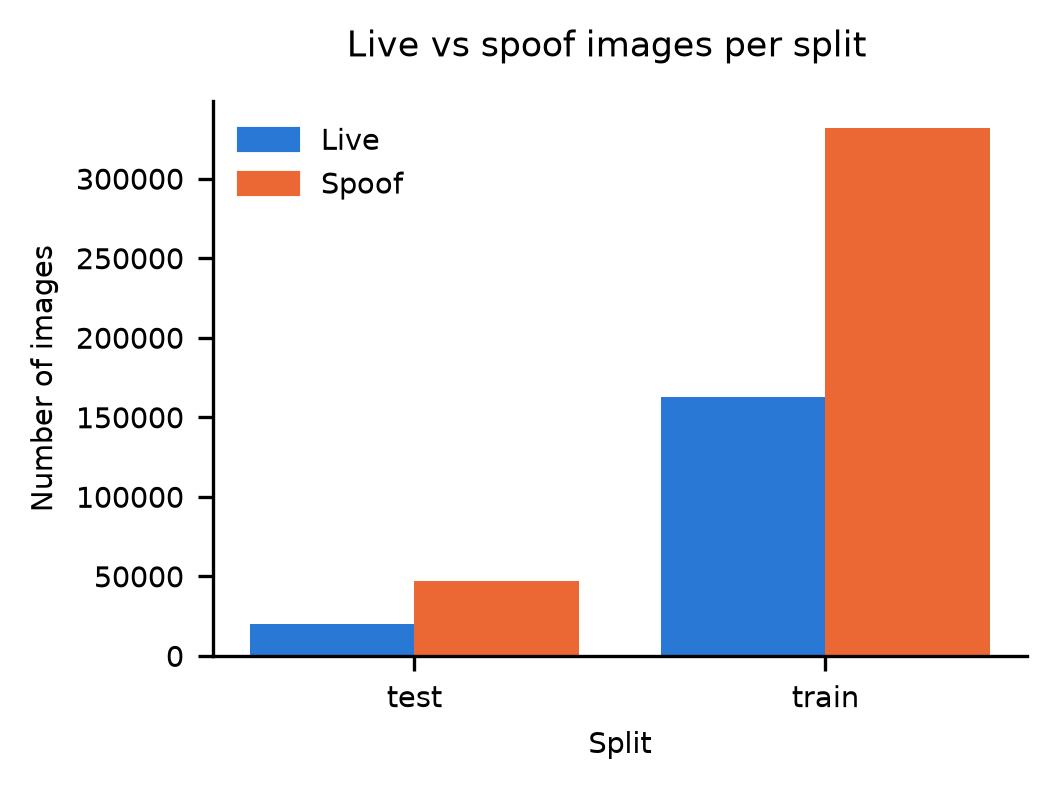

In [3]:
show('eda_live_vs_spoof')

The ten attack types are roughly balanced.

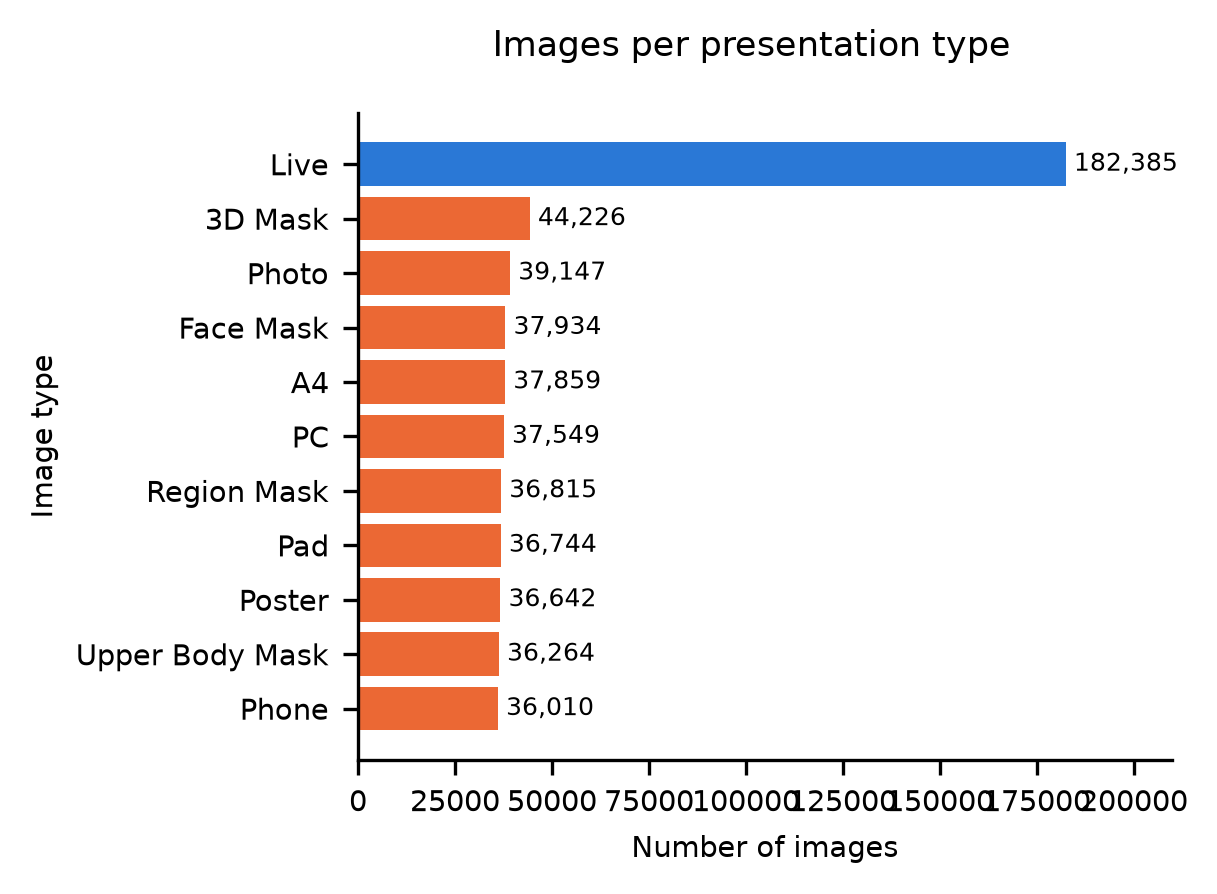

In [4]:
show('eda_spoof_types')

Subjects have many images each, so splits must keep each subject in one partition.

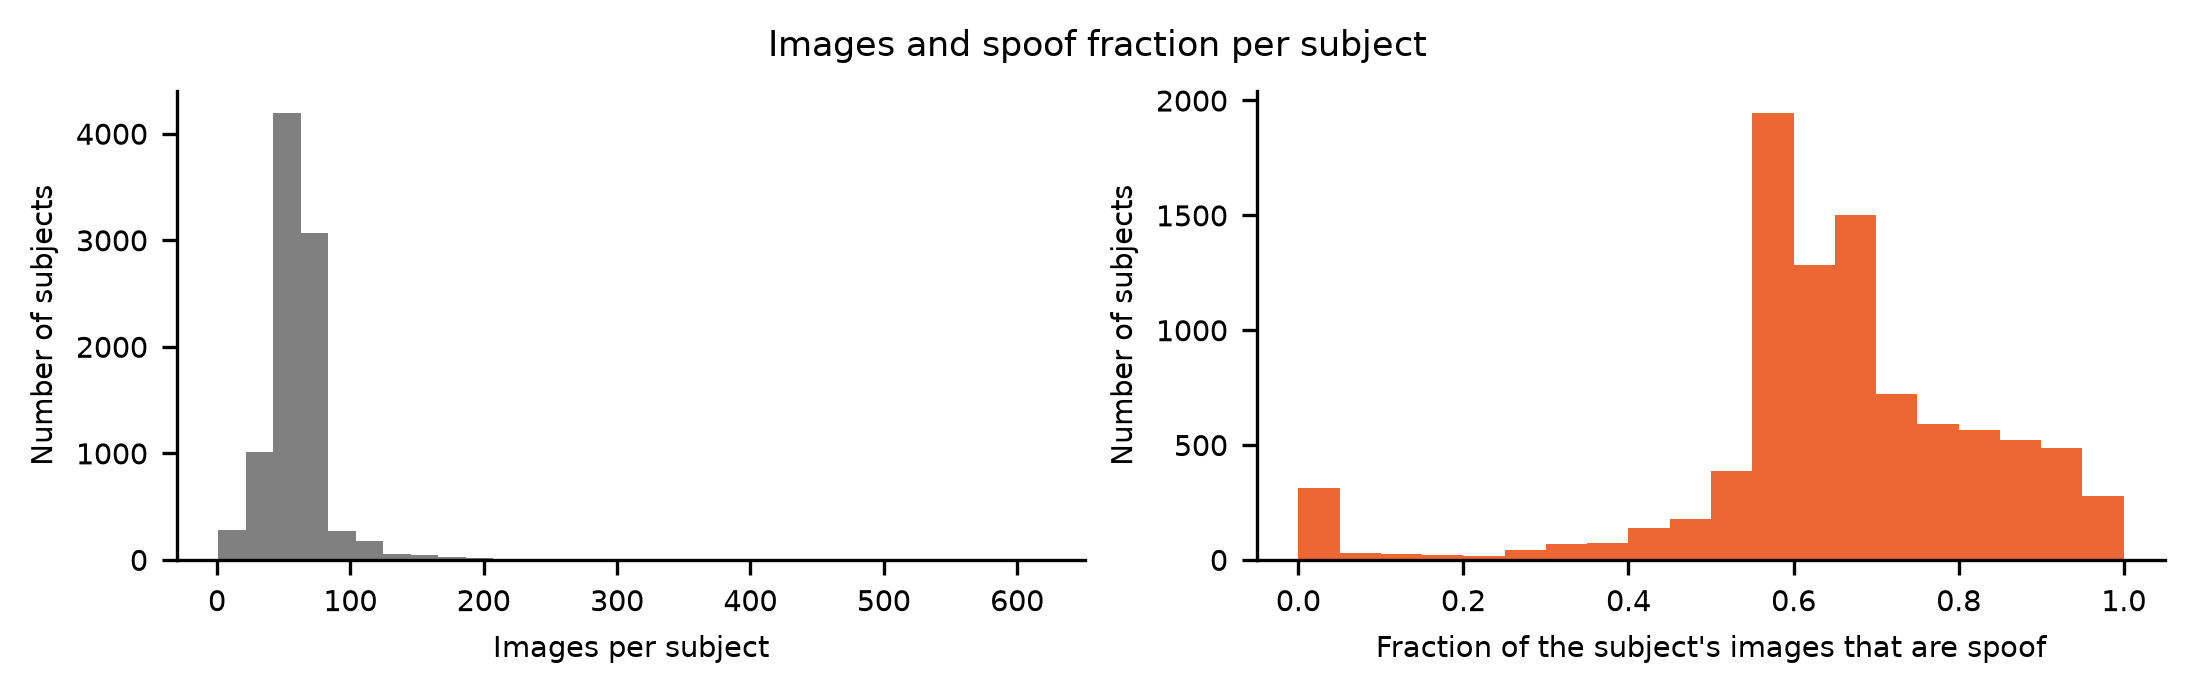

In [5]:
show('eda_subjects')

## Univariate analysis

No single image statistic separates live from spoof.

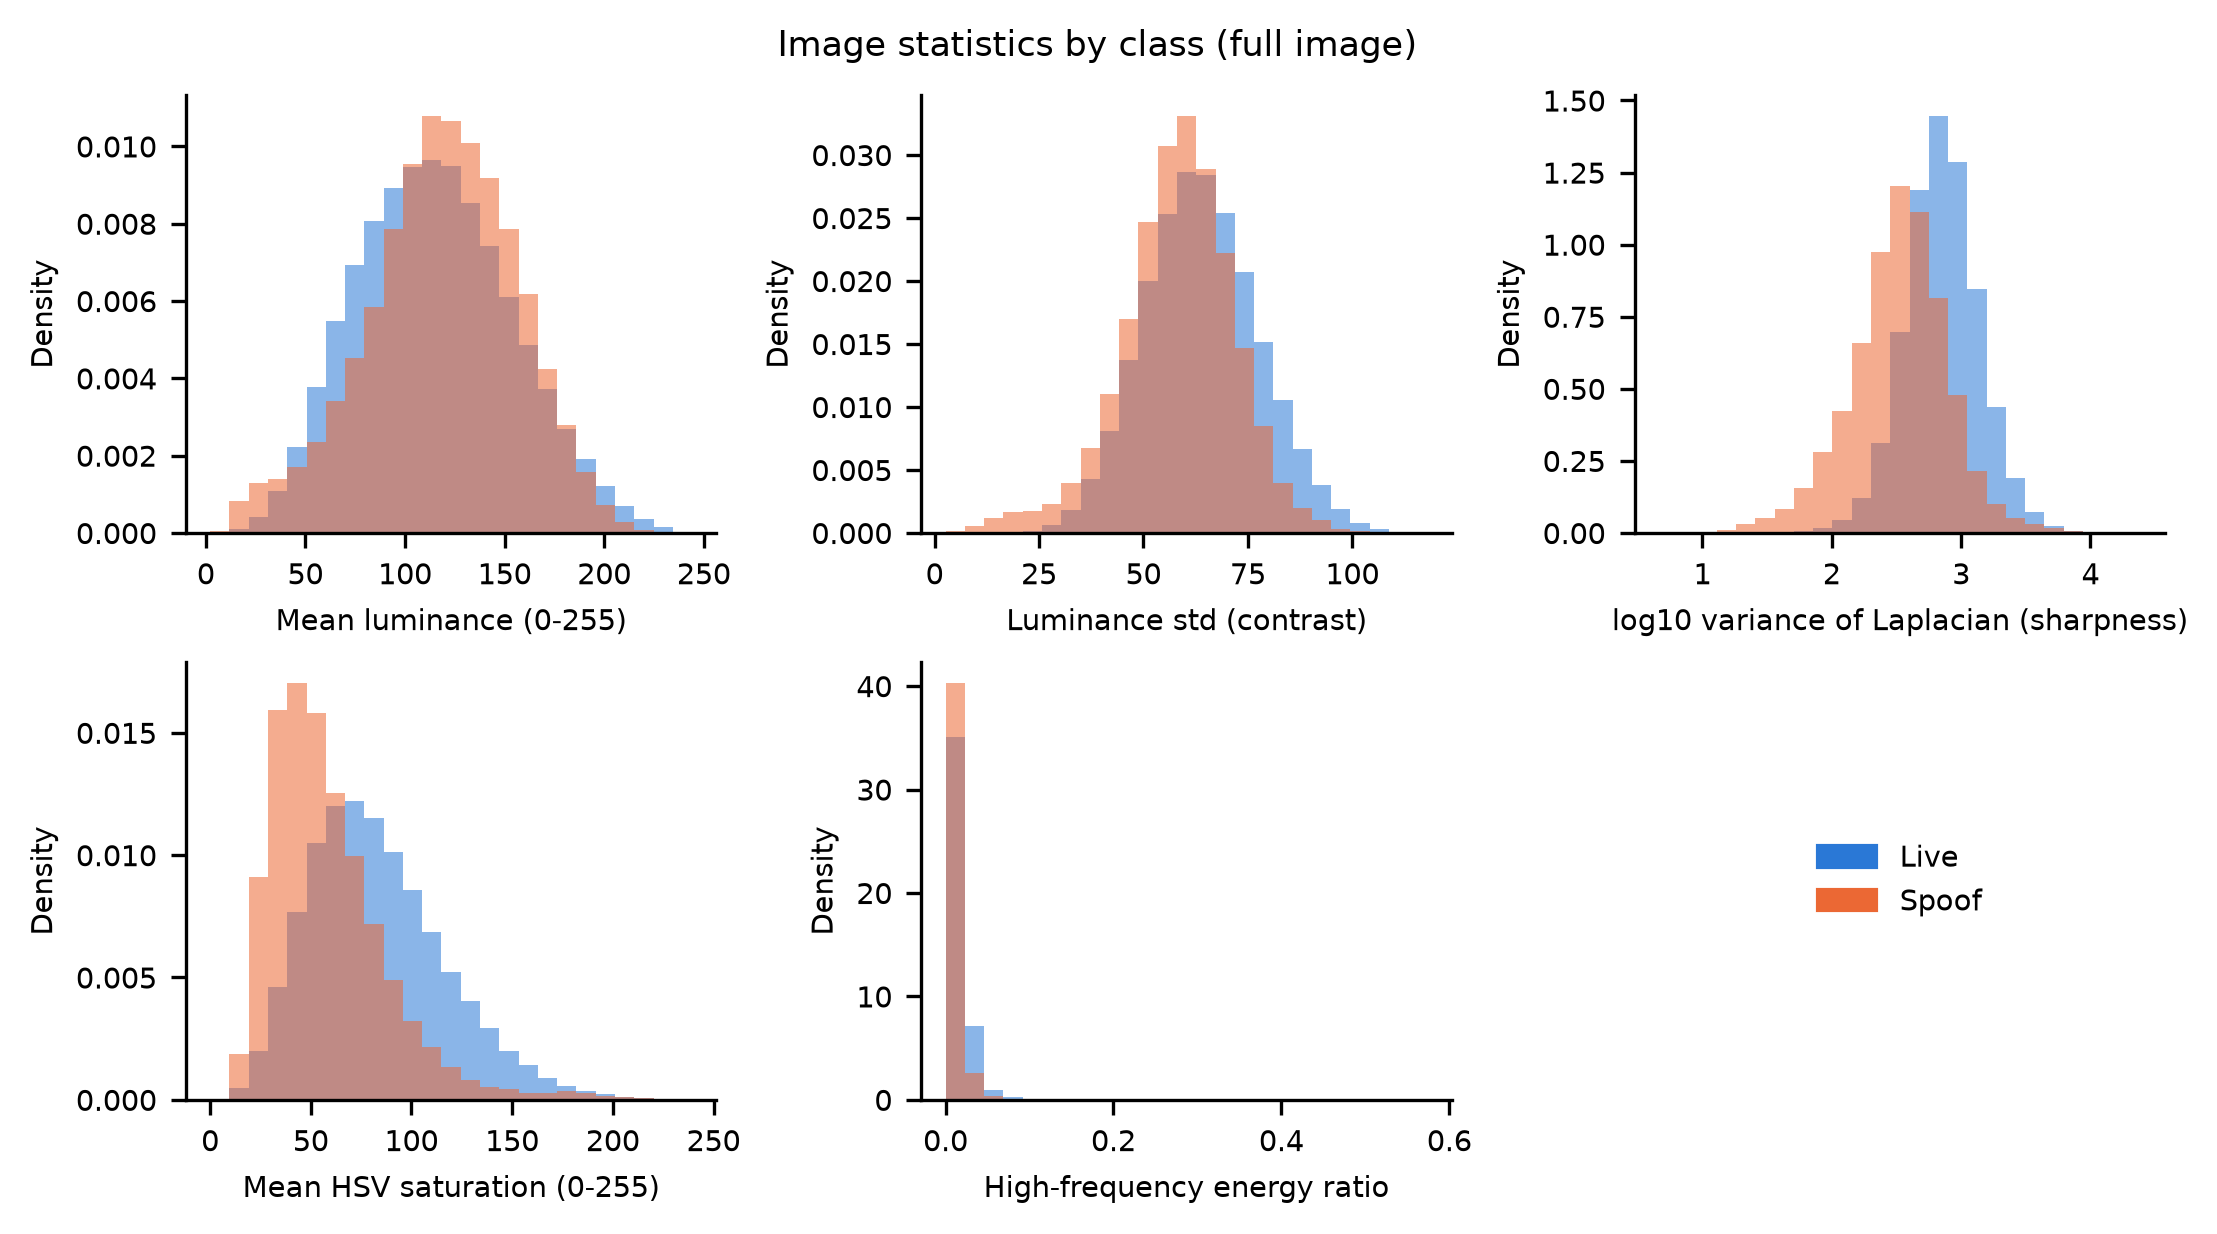

In [6]:
show('eda_feature_hists')

Each attack type has a different spread of image statistics.

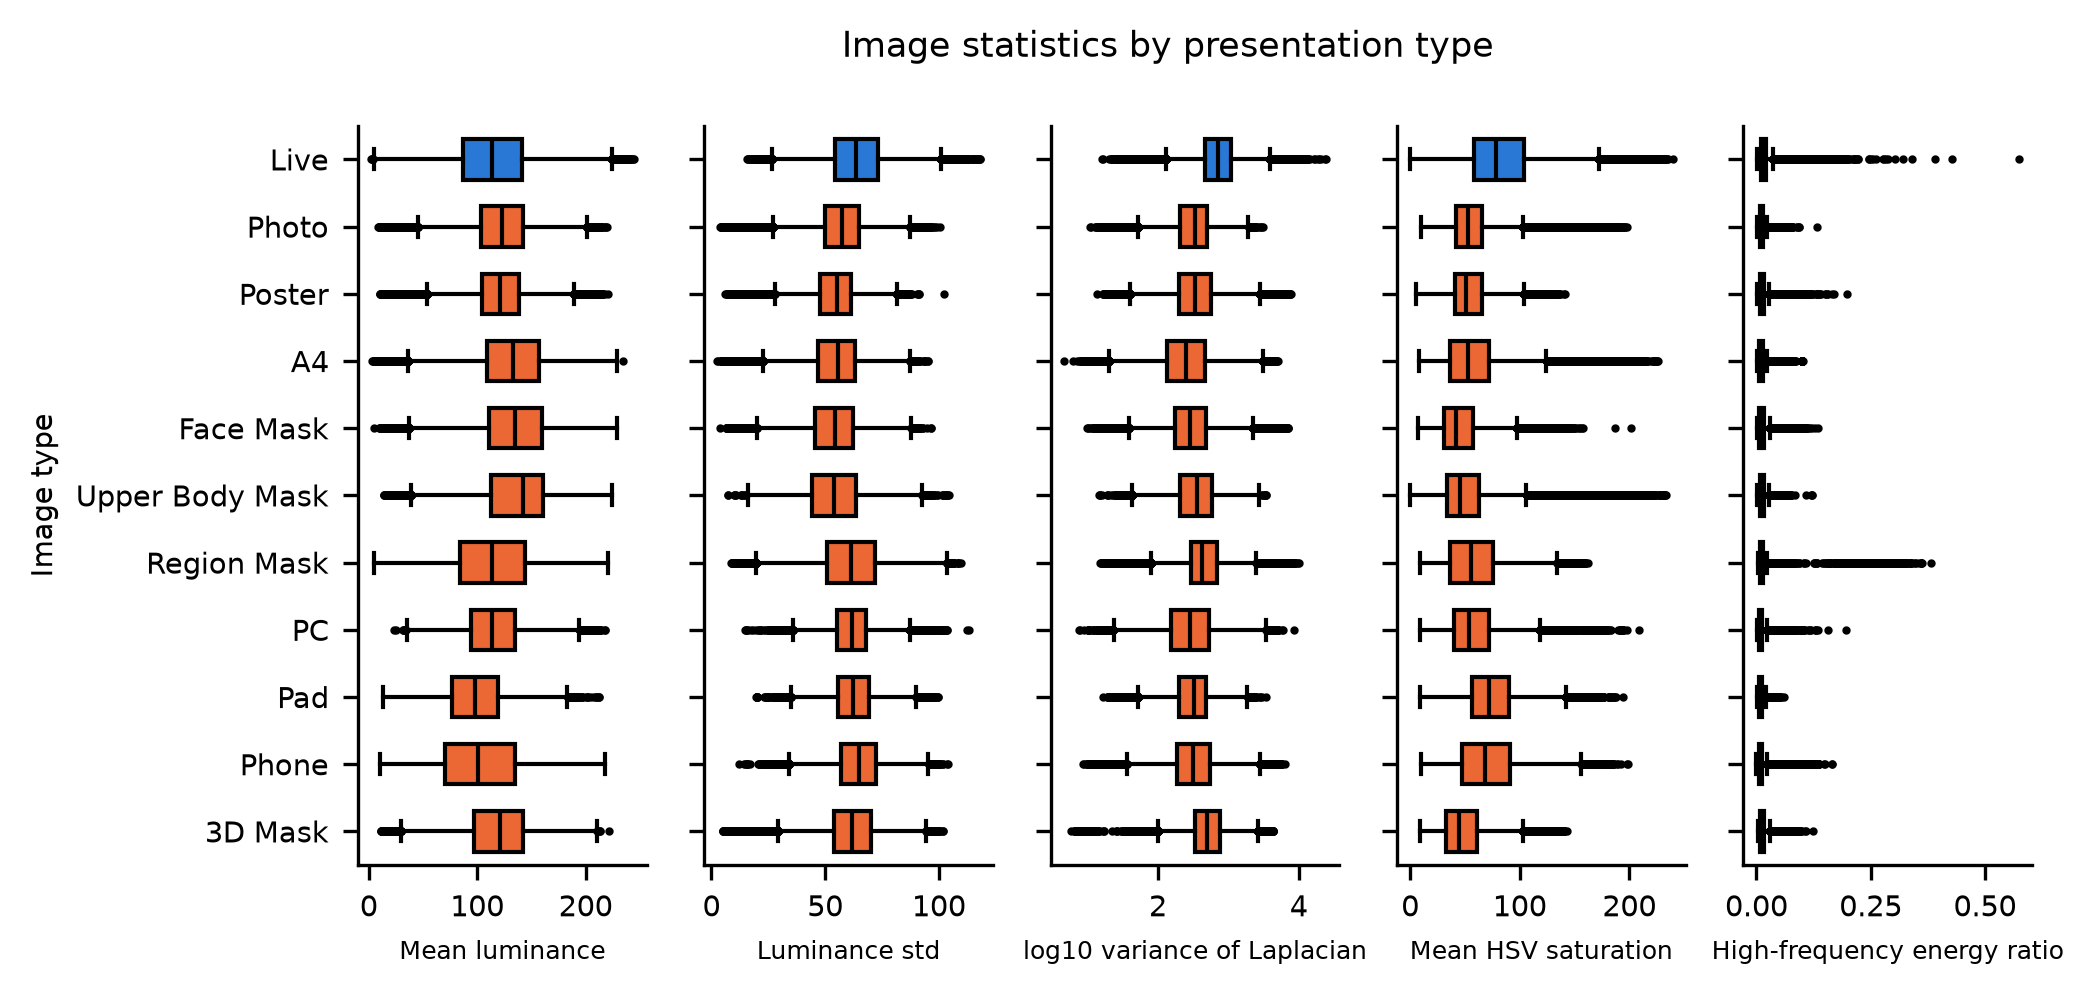

In [7]:
show('eda_feature_boxes')

## Bivariate analysis

Spearman correlation between image statistics (full image, face, background) and the label.

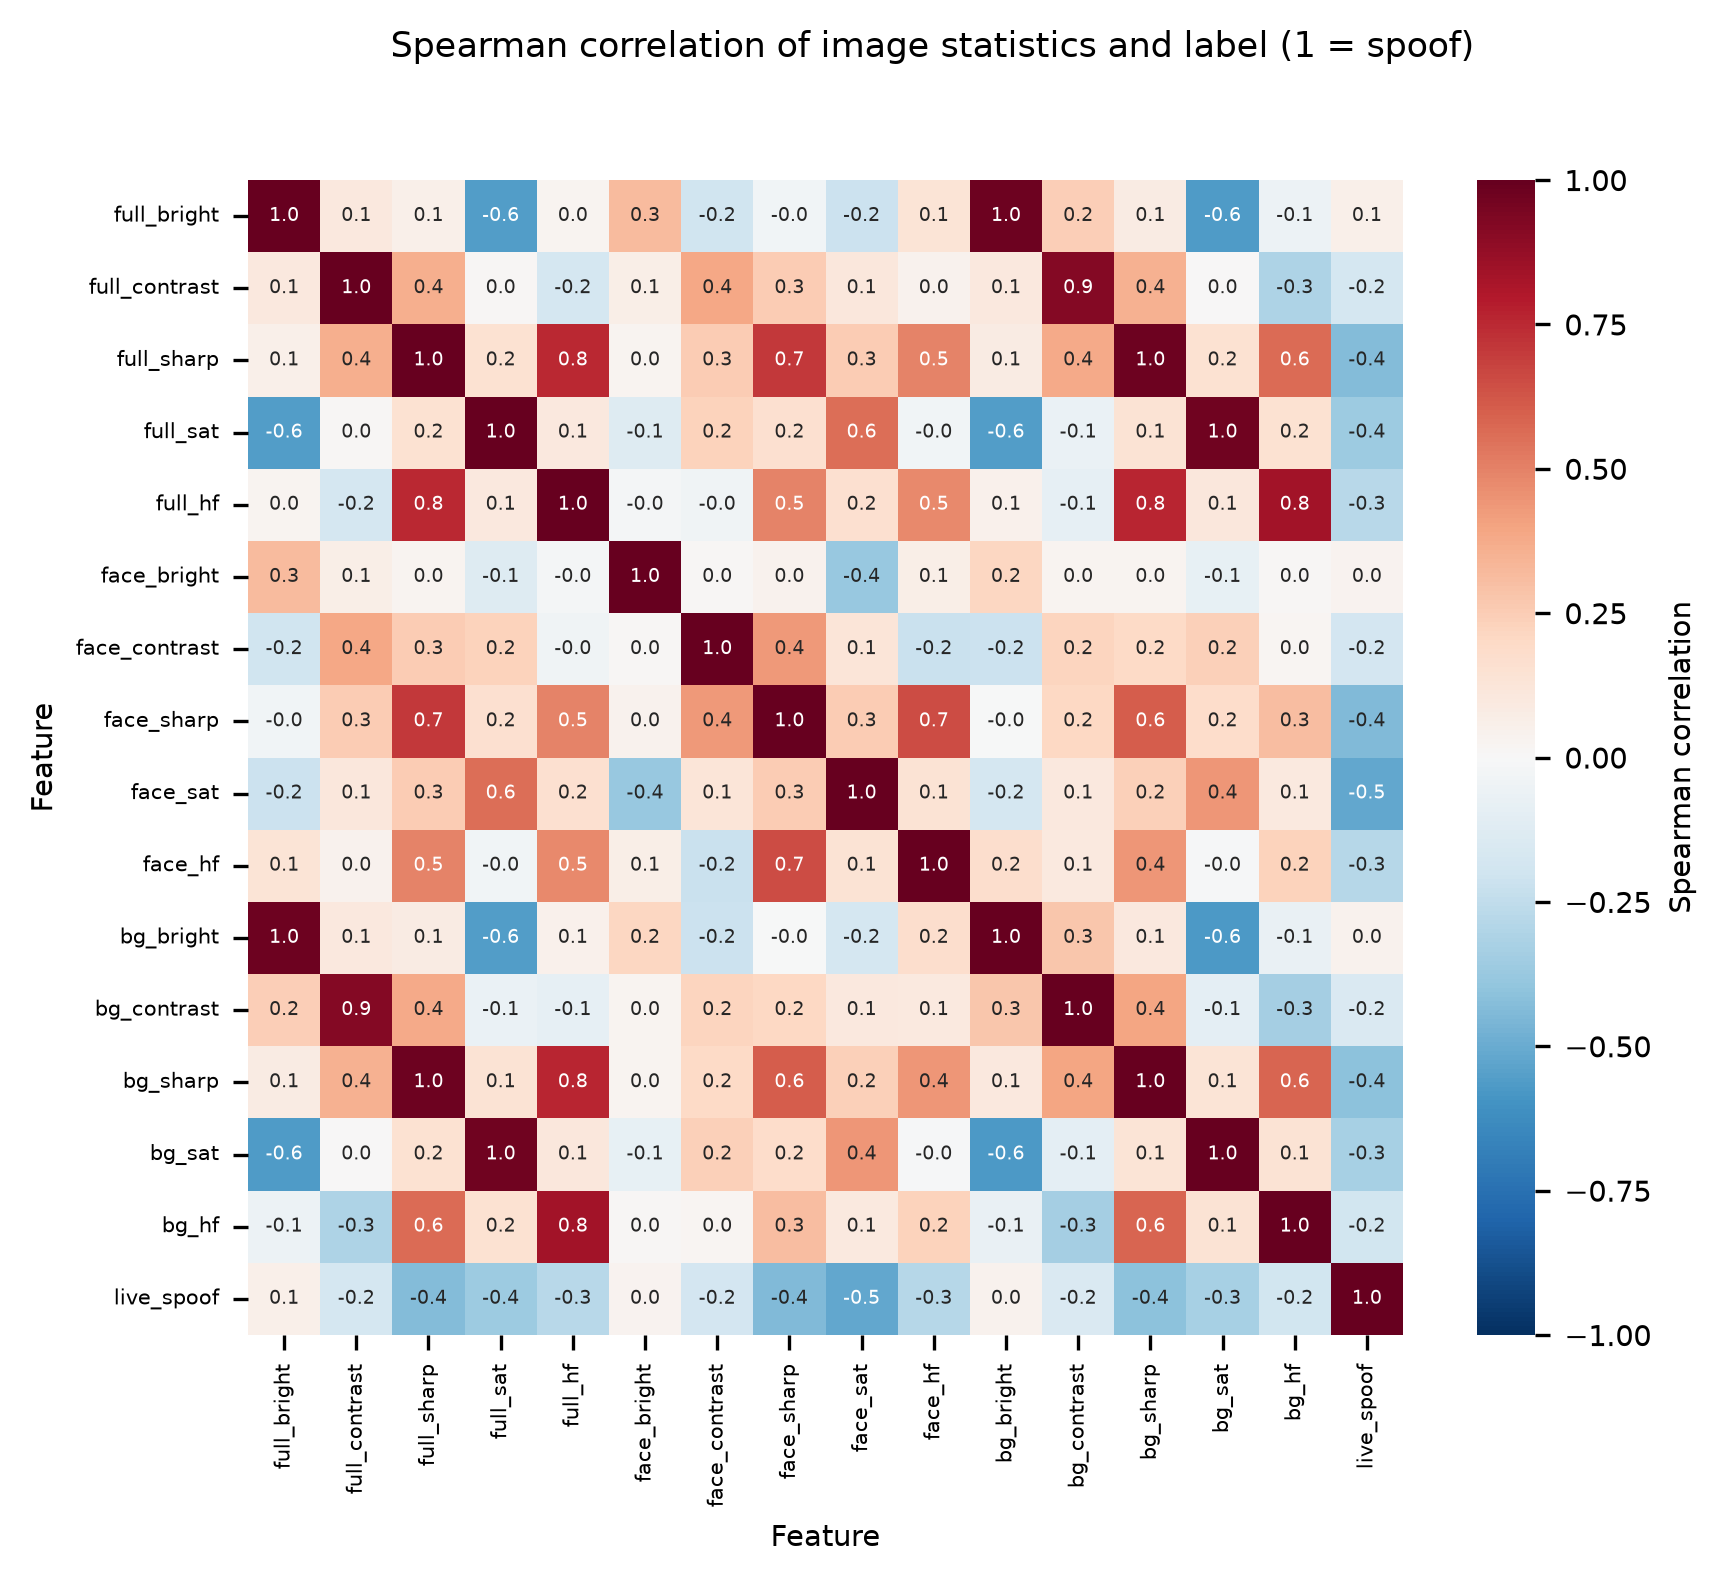

In [8]:
show('eda_correlation')

## Numbers used in the report

In [9]:
n_live = (labels['live_spoof'] == 0).sum()
n_spoof = (labels['live_spoof'] == 1).sum()
print(f"spoof:live = {n_spoof / n_live:.1f}:1 ({n_spoof:,} spoof, {n_live:,} live)")
print(f"median images per subject: {labels.groupby('subject_id').size().median():.0f}")

for feature in eda.FEATURES:
    live = eda.feature_values(stats, f'full_{feature}', 0)
    spoof = eda.feature_values(stats, f'full_{feature}', 1)
    print(f"KS statistic, {feature}: {scipy_stats.ks_2samp(live, spoof).statistic:.2f}")

ratio = stats['face_sharp'] / stats['bg_sharp']
print('median face/background sharpness ratio:', ratio.groupby(stats['live_spoof']).median().round(2).to_dict())

spoof:live = 2.1:1 (379,190 spoof, 182,385 live)
median images per subject: 60
KS statistic, bright: 0.08
KS statistic, contrast: 0.15
KS statistic, sharp: 0.41
KS statistic, sat: 0.34
KS statistic, hf: 0.24
median face/background sharpness ratio: {0: 1.13, 1: 1.03}


In [10]:
# share of each attack type captured indoors / outdoors
spoofs = labels[labels['live_spoof'] == 1]
table = pd.crosstab(spoofs['spoof_type'].map(data.SPOOF_TYPES), spoofs['environment'].map(data.ENVIRONMENT),
                    normalize='index')
table.round(2)

environment,Indoor,Outdoor
spoof_type,,
3D Mask,0.74,0.26
A4,0.81,0.19
Face Mask,0.76,0.24
PC,0.82,0.18
Pad,0.78,0.22
Phone,0.75,0.25
Photo,0.79,0.21
Poster,0.78,0.22
Region Mask,0.76,0.24
